# 08 — VAERS v11b: official results

The official MulTaBench evaluation of the submitted dataset, and how it compares with the benchmark. Data exploration and preprocessing are in notebook 02.

1. **Official results:** 5 learners × 4 conditions × 5 folds, both curation checks.
2. **Is the structured signal real?** A permutation test.
3. **How the dataset versions changed the gains.**
4. **Comparison with the 20 accepted MulTaBench text datasets.**

Inputs: `results/official_c955466/per_fold.csv` (official run), `research/data/vaers_v11b/vaers_v11b.csv`, `research/data/screens/version_screens_light_cat_folds012.csv`, and MulTaBench reference results (`research/data/learner_curation_results.csv`, `dataset_profiles.csv`). CPU, about one minute.

In [1]:
import sys, re, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve().parents[1]          # repository root (this file lives in research/notebooks)
sys.path.insert(0, str(ROOT))
from research.scripts.vaers import build_vaers as bv, refine_v9 as rv

DATA = ROOT / "research/data/vaers_v11b/vaers_v11b.csv"
RESULTS = ROOT / "results/official_c955466/per_fold.csv"
REF = ROOT / "research/data"

# Chart style: validated categorical palette (slots 1-4), recessive axes, text in ink colours.
BLUE, ORANGE, AQUA, YELLOW, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#a3a29c"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e7e6e2"
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11, "axes.titlecolor": INK})
pd.set_option("display.precision", 3)

df = pd.read_csv(DATA, keep_default_na=False, dtype=str)
y = df.serious.astype(int).to_numpy()
STRUCT_NUM = ["age_years", "onset_days", "n_vaccines", "report_year"]
STRUCT_CAT = ["sex", "state", "vax_type", "vax_manu", "vax_dose_series", "vax_route", "vax_site", "admin_by"]
TEXT = ["narrative_onset", "patient_background"]
print(f"{len(df):,} reports, {y.sum():,} serious ({y.mean():.1%}), {df.shape[1]} columns")

18,859 reports, 4,900 serious (26.0%), 16 columns


## 1. Official MulTaBench results

Run once with the official `benchmark.py` at MulTaBench commit `c955466` (the `master` branch as of 26 Jul 2026), 5 learners × 4 conditions × 5 folds = 100 runs, A100 GPU. Score = AUROC on each fold's test set; a learner's score per condition is the mean of its 5 folds.

In [2]:
pf = pd.read_csv(RESULTS)
COND = ["no_text", "text_only", "all", "ft"]
NAMES = {"no_text": "Structured", "text_only": "Text", "all": "Joint Frozen", "ft": "Joint TAR"}
LEARN = {"light": "LightGBM", "cat": "CatBoost", "tabm": "TabM", "tabpfnv2": "TabPFN-v2", "tabpfnv2p5": "TabPFN-2.5"}
m = pf.groupby("model")[COND].mean().loc[list(LEARN)]
m["Joint gain"] = m["all"] - m[["no_text", "text_only"]].max(axis=1)
m["TAR gain"] = m["ft"] - m["all"]
table = m.rename(index=LEARN, columns=NAMES)
table["Joint pass"] = table["Joint gain"] > 0; table["TAR pass"] = table["TAR gain"] > 0
print(f"Joint Signal: {int(table['Joint pass'].sum())}/5 learners, TAR Gain: {int(table['TAR pass'].sum())}/5 learners "
      f"(need 3/5 each). Median gains: Joint {m['Joint gain'].median():+.3f}, TAR {m['TAR gain'].median():+.3f}")
table.round(3)

Joint Signal: 5/5 learners, TAR Gain: 5/5 learners (need 3/5 each). Median gains: Joint +0.031, TAR +0.020


,Structured,Text,Joint Frozen,Joint TAR,Joint gain,TAR gain,Joint pass,TAR pass
model,,,,,,,,
LightGBM,0.721,0.778,0.809,0.839,0.031,0.030,True,True
CatBoost,0.739,0.787,0.823,0.843,0.036,0.020,True,True
TabM,0.725,0.799,0.832,0.847,0.033,0.015,True,True
TabPFN-v2,0.735,0.795,0.821,0.843,0.027,0.022,True,True
TabPFN-2.5,0.740,0.805,0.835,0.851,0.029,0.016,True,True


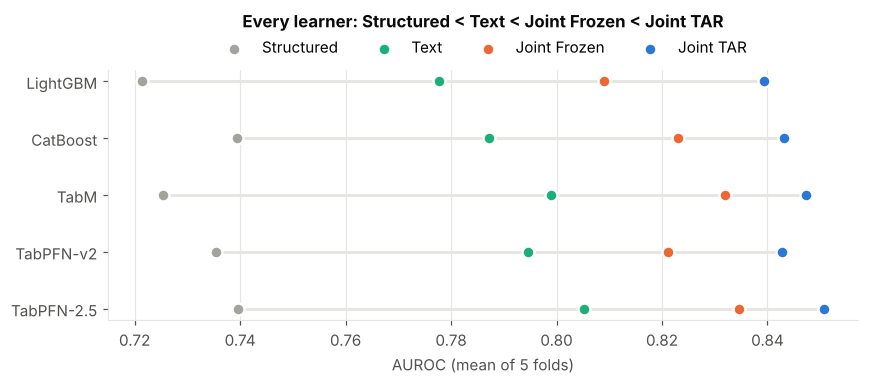

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
cols = {"no_text": GRAY, "text_only": AQUA, "all": ORANGE, "ft": BLUE}
for i, mdl in enumerate(LEARN):
    vals = m.loc[mdl, COND]
    ax.plot([vals.min(), vals.max()], [i, i], color=GRID, lw=2, zorder=1)
    for c in COND:
        ax.scatter(vals[c], i, color=cols[c], s=60, zorder=3, edgecolor="white", linewidth=1.5,
                   label=NAMES[c] if i == 0 else None)
ax.set_yticks(range(len(LEARN))); ax.set_yticklabels(LEARN.values()); ax.invert_yaxis()
ax.set_xlabel("AUROC (mean of 5 folds)"); ax.grid(axis="y", visible=False)
ax.legend(ncol=4, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0))
ax.set_title("Every learner: Structured < Text < Joint Frozen < Joint TAR", pad=28)
plt.tight_layout(); plt.show()

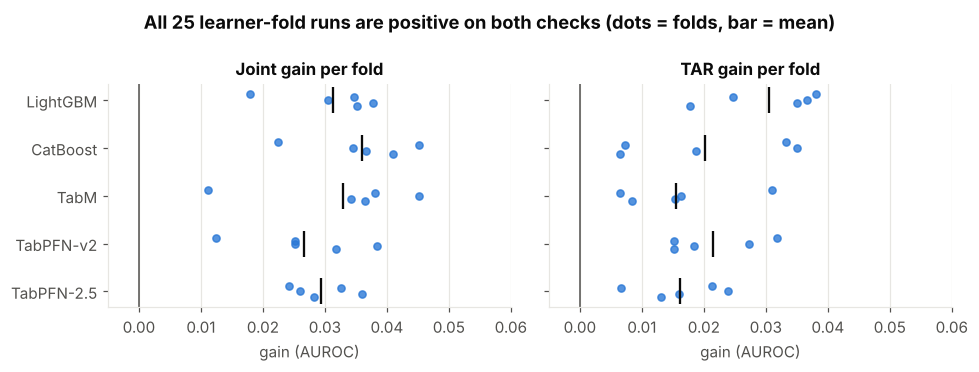

,Joint gain,TAR gain,positive runs
folds,,,
0-2 (used when choosing the dataset version),0.028,0.024,15/15
3-4 (never seen before the official run),0.036,0.016,10/10


In [4]:
pf["learner"] = pf.model.map(LEARN)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, g, title in [(axes[0], "joint_gain", "Joint gain per fold"), (axes[1], "tar_gain", "TAR gain per fold")]:
    for i, mdl in enumerate(LEARN):
        v = pf.loc[pf.model == mdl, g]
        ax.scatter(v, np.full(len(v), i) + np.linspace(-0.12, 0.12, len(v)), color=BLUE, s=22, alpha=0.8, zorder=3)
        ax.scatter(v.mean(), i, marker="|", s=300, color=INK, zorder=4)
    ax.axvline(0, color=INK2, lw=1); ax.set_title(title); ax.grid(axis="y", visible=False)
    ax.set_xlim(-0.005, 0.06); ax.set_xlabel("gain (AUROC)")
axes[0].set_yticks(range(len(LEARN))); axes[0].set_yticklabels(LEARN.values()); axes[0].invert_yaxis()
fig.suptitle("All 25 learner-fold runs are positive on both checks (dots = folds, bar = mean)", fontweight="bold", color=INK)
plt.tight_layout(); plt.show()

seen = pf.fold <= 2
pd.DataFrame({"folds": ["0-2 (used when choosing the dataset version)", "3-4 (never seen before the official run)"],
              "Joint gain": [pf[seen].joint_gain.mean(), pf[~seen].joint_gain.mean()],
              "TAR gain": [pf[seen].tar_gain.mean(), pf[~seen].tar_gain.mean()],
              "positive runs": [f"{(pf[seen][['joint_gain','tar_gain']] > 0).all(axis=1).sum()}/{seen.sum()}",
                                f"{(pf[~seen][['joint_gain','tar_gain']] > 0).all(axis=1).sum()}/{(~seen).sum()}"]}).set_index("folds").round(3)

**Insight.** 25/25 runs positive on both checks (smallest TAR gain +0.0065). Folds 3–4, never seen while choosing the version, stay positive too (TAR +0.016).

## 2. Is 0.72 (structured only) real signal or noise?

Permutation test: train LightGBM on the 12 structured columns with the real labels, then 30 times with shuffled labels, and score each on the same held-out 10% (about 1,900 reports, like an official fold).

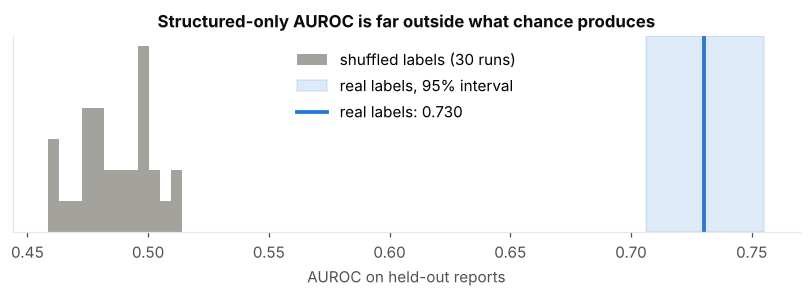

shuffled: mean 0.486, max 0.514 | real 0.730, 95% interval 0.706-0.755
official structured-only scores: min 0.699 over all 25 learner-fold runs


In [5]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
Xs = pd.DataFrame({c: pd.to_numeric(df[c], errors="coerce") for c in STRUCT_NUM})
for c in STRUCT_CAT:
    Xs[c] = df[c].astype("category")
tr, te = train_test_split(np.arange(len(df)), test_size=0.1, stratify=y, random_state=42)
def fit_score(labels):
    m = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, verbose=-1, random_state=42)
    m.fit(Xs.iloc[tr], labels[tr])
    return m.predict_proba(Xs.iloc[te])[:, 1]
p_real = fit_score(y)
real = roc_auc_score(y[te], p_real)
rng = np.random.default_rng(0)
null = [roc_auc_score(y[te], fit_score(rng.permutation(y))) for _ in range(30)]
boot = [roc_auc_score(y[te][i], p_real[i]) for i in (rng.integers(0, len(te), len(te)) for _ in range(1000))]

fig, ax = plt.subplots(figsize=(7.5, 2.8))
ax.hist(null, bins=12, color=GRAY, label="shuffled labels (30 runs)")
ax.axvspan(*np.percentile(boot, [2.5, 97.5]), color=BLUE, alpha=0.15, label="real labels, 95% interval")
ax.axvline(real, color=BLUE, lw=2.5, label=f"real labels: {real:.3f}")
ax.set_xlabel("AUROC on held-out reports"); ax.set_yticks([]); ax.grid(visible=False)
ax.legend(frameon=False, loc="upper center"); ax.set_title("Structured-only AUROC is far outside what chance produces")
plt.tight_layout(); plt.show()
print(f"shuffled: mean {np.mean(null):.3f}, max {np.max(null):.3f} | real {real:.3f}, 95% interval {np.percentile(boot, 2.5):.3f}-{np.percentile(boot, 97.5):.3f}")
print(f"official structured-only scores: min {pf.no_text.min():.3f} over all 25 learner-fold runs")

**Insight.** Shuffled labels give about 0.50; the real labels give about 0.72, with a 95% interval far above the shuffled range. The structured columns carry real, if modest, signal.

## 3. How the dataset versions changed the gains

Same learners (LightGBM, CatBoost) and folds (0–2) for every version, so the bars are comparable. Values: `research/data/screens/version_screens_light_cat_folds012.csv` (screen runs, paper-version code).

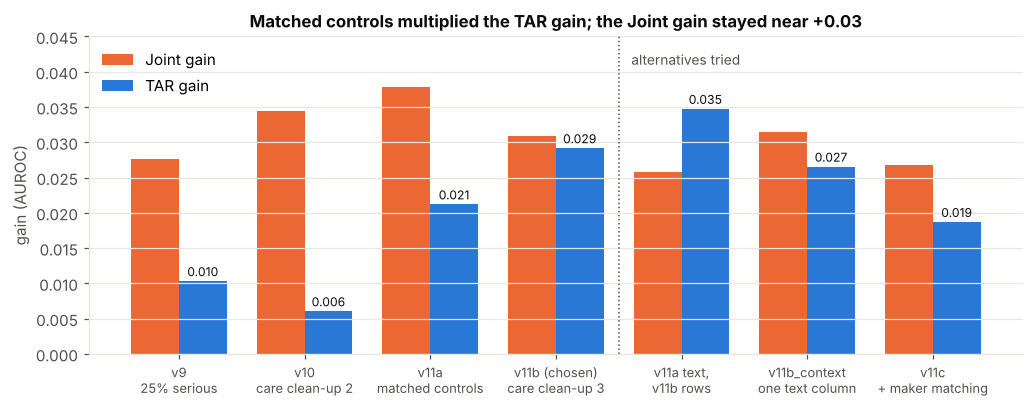

official run, same learners and folds: Joint +0.0309, TAR +0.0292 (screen: +0.0309, +0.0292)


In [6]:
vs = pd.read_csv(REF / "screens/version_screens_light_cat_folds012.csv").groupby("version")[["joint_gain", "tar_gain"]].mean()
order = [("v9", "v9\n25% serious"), ("v10", "v10\ncare clean-up 2"), ("v11a", "v11a\nmatched controls"),
         ("v11b", "v11b (chosen)\ncare clean-up 3"), ("v11a_control", "v11a text,\nv11b rows"),
         ("v11b_context", "v11b_context\none text column"), ("v11c", "v11c\n+ maker matching")]
vs = vs.loc[[k for k, _ in order]]
x = np.arange(len(vs)); w = 0.38
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.bar(x - w / 2, vs.joint_gain, w, color=ORANGE, label="Joint gain")
ax.bar(x + w / 2, vs.tar_gain, w, color=BLUE, label="TAR gain")
for i, (j, t) in enumerate(zip(vs.joint_gain, vs.tar_gain)):
    ax.text(i + w / 2, t + 0.0007, f"{t:.3f}", ha="center", fontsize=8, color=INK)
ax.axvline(3.5, color=INK2, lw=1, ls=":"); ax.text(3.6, 0.041, "alternatives tried", color=INK2, fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([l for _, l in order], fontsize=8.5); ax.set_ylabel("gain (AUROC)")
ax.set_ylim(0, 0.045); ax.grid(axis="x", visible=False); ax.legend(frameon=False, loc="upper left")
ax.set_title("Matched controls multiplied the TAR gain; the Joint gain stayed near +0.03")
plt.tight_layout(); plt.show()
q = pf[pf.model.isin(["light", "cat"]) & (pf.fold <= 2)]
print(f"official run, same learners and folds: Joint {q.joint_gain.mean():+.4f}, TAR {q.tar_gain.mean():+.4f} "
      f"(screen: {vs.loc['v11b', 'joint_gain']:+.4f}, {vs.loc['v11b', 'tar_gain']:+.4f})")

**Insight.** TAR gain went from about +0.006–0.010 (v9, v10) to +0.021–0.035 once controls were matched. v11a vs "v11a text on v11b rows" differ by only 4 reports yet by 0.013 in TAR gain: differences under about 0.01 are split noise. v11b was chosen as the cleanest version (care text removed) within that noise band. The official run reproduces the v11b screen exactly on these folds.

## 4. Against the 20 accepted MulTaBench text datasets

Reference values come from MulTaBench's published per-learner results (notebook 01); each dataset is placed at its median gain over the five learners.

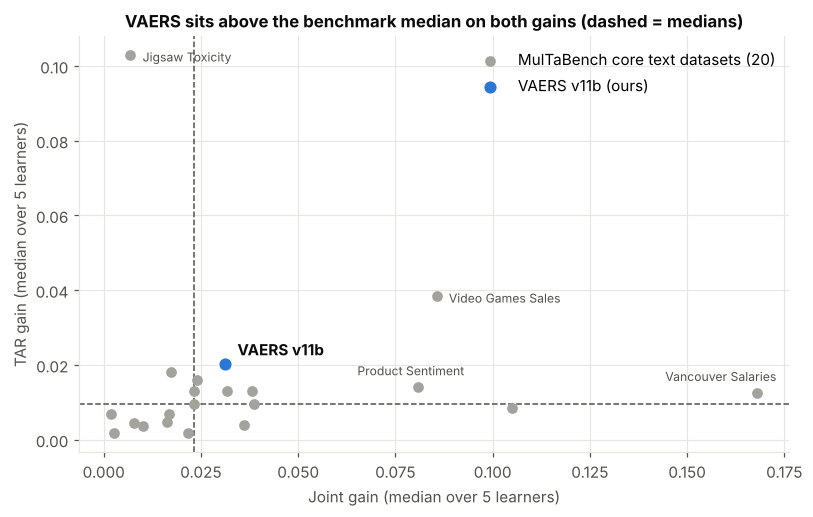

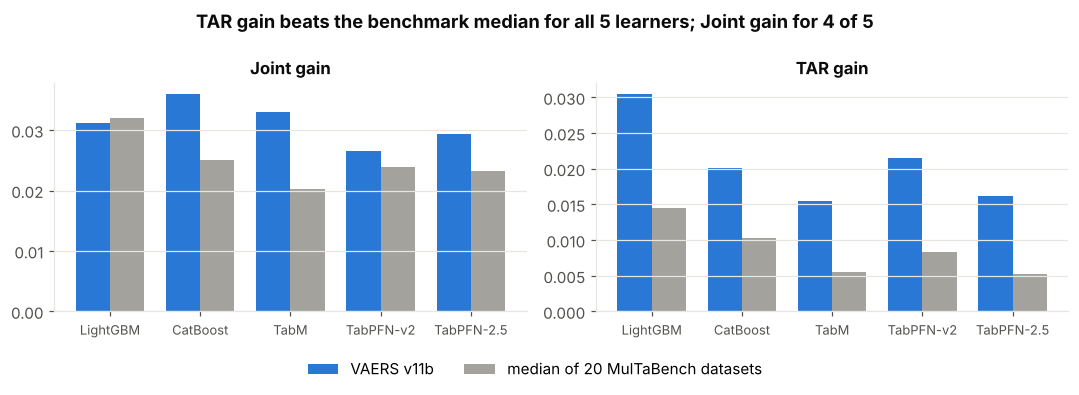

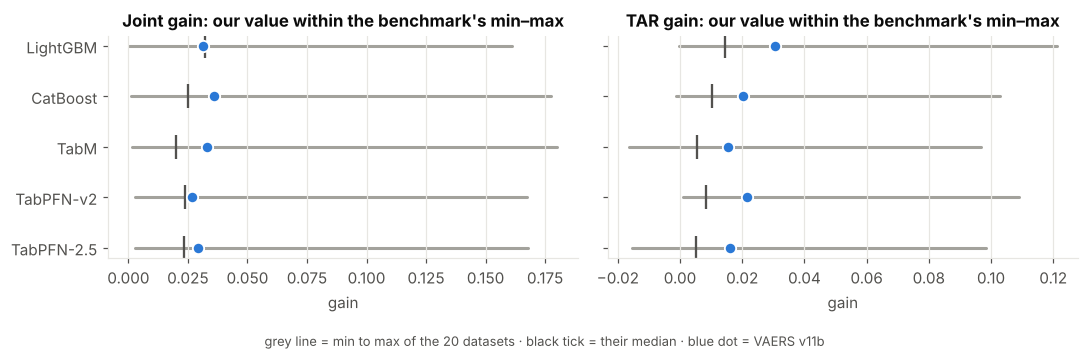

,TAR rank,Joint gain,TAR gain
Jigsaw Toxicity,1,0.007,0.103
Video Games Sales,2,0.086,0.038
VAERS v11b (ours),3,0.031,0.020
Rotten Tomatoes,4,0.017,0.018
Baby Products,5,0.024,0.016
Product Sentiment,6,0.081,0.014


In [7]:
ref = pd.read_csv(REF / "learner_curation_results.csv")
prof = pd.read_csv(REF / "dataset_profiles.csv")
core = prof[prof.released_collection == "core"].set_index("dataset_id")
g = ref[ref.dataset_id.isin(core.index)].groupby("dataset_id")[["unrounded_joint_gain", "unrounded_tar_gain"]].median()
g["name"] = core.dataset_name
ours = (m["Joint gain"].median(), m["TAR gain"].median())

fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.scatter(g.unrounded_joint_gain, g.unrounded_tar_gain, color=GRAY, s=36, zorder=3, label="MulTaBench core text datasets (20)")
ax.scatter(*ours, color=BLUE, s=90, zorder=4, edgecolor="white", linewidth=1.5, label="VAERS v11b (ours)")
ax.annotate("VAERS v11b", ours, xytext=(8, 6), textcoords="offset points", color=INK, fontweight="bold")
offsets = {"Jigsaw Toxicity": (8, -4), "Video Games Sales": (8, -4), "Vancouver Salaries": (-60, 8), "Product Sentiment": (-40, 8)}
for n, off in offsets.items():
    r = g[g.name == n].iloc[0]
    ax.annotate(n, (r.unrounded_joint_gain, r.unrounded_tar_gain), xytext=off, textcoords="offset points", fontsize=8, color=INK2)
ax.axvline(g.unrounded_joint_gain.median(), color=INK2, lw=1, ls="--"); ax.axhline(g.unrounded_tar_gain.median(), color=INK2, lw=1, ls="--")
ax.set_xlabel("Joint gain (median over 5 learners)"); ax.set_ylabel("TAR gain (median over 5 learners)")
ax.set_title("VAERS sits above the benchmark median on both gains (dashed = medians)")
ax.legend(frameon=False, loc="upper right"); plt.tight_layout(); plt.show()

REFMAP = {"light": "LightGBM", "cat": "CatBoost", "tabm": "TabM", "tabpfnv2": "TabPFNv2", "tabpfnv2p5": "TabPFN-2.5"}
core_ref = ref[ref.dataset_id.isin(core.index)]
stats = {}
for gain, col in [("Joint gain", "unrounded_joint_gain"), ("TAR gain", "unrounded_tar_gain")]:
    by = core_ref.groupby("model_name")[col]
    stats[gain] = pd.DataFrame({"ours": [m.loc[k, gain] for k in REFMAP], "median": [by.median()[v] for v in REFMAP.values()],
                                "min": [by.min()[v] for v in REFMAP.values()], "max": [by.max()[v] for v in REFMAP.values()]},
                               index=list(LEARN.values()))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, gain in zip(axes, stats):
    t = stats[gain]; xx = np.arange(len(t))
    ax.bar(xx - 0.19, t["ours"], 0.38, color=BLUE, label="VAERS v11b")
    ax.bar(xx + 0.19, t["median"], 0.38, color=GRAY, label="median of 20 MulTaBench datasets")
    ax.set_xticks(xx); ax.set_xticklabels(t.index, fontsize=8.5); ax.set_title(gain); ax.grid(axis="x", visible=False)
fig.legend(*axes[0].get_legend_handles_labels(), frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.04))
fig.suptitle("TAR gain beats the benchmark median for all 5 learners; Joint gain for 4 of 5", fontweight="bold", color=INK)
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, gain in zip(axes, stats):
    t = stats[gain]
    for i, (_, r) in enumerate(t.iterrows()):
        ax.plot([r["min"], r["max"]], [i, i], color=GRAY, lw=2, solid_capstyle="round", zorder=1)
        ax.scatter(r["median"], i, marker="|", s=250, color=INK2, zorder=2)
        ax.scatter(r["ours"], i, color=BLUE, s=55, zorder=3, edgecolor="white", linewidth=1.2)
    ax.set_title(f"{gain}: our value within the benchmark's min–max"); ax.grid(axis="y", visible=False); ax.set_xlabel("gain")
axes[0].set_yticks(range(5)); axes[0].set_yticklabels(stats["TAR gain"].index); axes[0].invert_yaxis()
fig.text(0.5, 0.0, "grey line = min to max of the 20 datasets · black tick = their median · blue dot = VAERS v11b",
         ha="center", fontsize=8.5, color=INK2)
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

rank = pd.concat([g.set_index("name")[["unrounded_joint_gain", "unrounded_tar_gain"]],
                  pd.DataFrame({"unrounded_joint_gain": [ours[0]], "unrounded_tar_gain": [ours[1]]}, index=["VAERS v11b (ours)"])])
rank.columns = ["Joint gain", "TAR gain"]
rank = rank.sort_values("TAR gain", ascending=False)
rank.insert(0, "TAR rank", range(1, len(rank) + 1))
rank.head(6).round(4)

**Insight.** TAR gain above the benchmark median for all 5 learners (about 2× overall), Joint gain for 4 of 5 (LightGBM about equal); TAR gain 3rd of 21 (after Jigsaw and Video Games). Reference values come from the paper's own runs (regression datasets use R², as in MulTaBench).

## 5. Class balance and the metric

- **26% positive** is set by the matched-control design (all serious reports plus up to three matched non-serious reports each). In all of VAERS, serious reports are roughly 8%. This is a case-control sample, stated as such in the paper.
- **AUROC** ranks reports and does not depend on a decision threshold, so the 26/74 split needs no reweighting; the official code also stratifies its splits, so every test fold keeps the same balance.
- **Test folds** hold about 1,885 reports each (about 490 serious), so a single AUROC has a standard error of roughly ±0.01. That is why we report 5 folds and look at per-fold consistency, not a single number.

## Summary

| Question | Answer |
| --- | --- |
| Does the text add beyond the table? | Yes: Joint Frozen beats both single modalities on 5/5 learners, median +0.031 |
| Does target-aware fine-tuning help? | Yes: TAR beats Joint Frozen on 5/5 learners and 25/25 runs, median +0.020 |
| Is the structured signal real? | 0.73 vs about 0.49 with shuffled labels |
| Is the text clean? | Yes, see notebook 02 (zero care or outcome words; top words are symptoms) |
| How does it compare? | Above the benchmark median on both gains; TAR gain 3rd of 21 |